In [15]:
# @title Default title text
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("winequality-red.csv")

print("First five rows:")
print(df.head())

print



First five rows:
   fixed acidity  volatile acidity  citric acid  ...  sulphates  alcohol  quality
0            7.4              0.70         0.00  ...       0.56      9.4        5
1            7.8              0.88         0.00  ...       0.68      9.8        5
2            7.8              0.76         0.04  ...       0.65      9.8        5
3           11.2              0.28         0.56  ...       0.58      9.8        6
4            7.4              0.70         0.00  ...       0.56      9.4        5

[5 rows x 12 columns]


In [16]:
print("\nDataset Shape:")
print(df.shape)



Dataset Shape:
(1599, 12)


In [17]:
print("\ncolumn values")
print(df.columns)


column values
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')


In [18]:
print("\nMissing values")
print(df.isnull().sum())


Missing values
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [21]:
x=df.drop("quality",axis=1)
y=df["quality"]

In [24]:
normalizer=MinMaxScaler()
X_normalized=normalizer.fit_transform(x)
print("\nNormalized data(first five rows):")
print(pd.DataFrame(X_normalized, columns=x.columns).head().round(3))


Normalized data(first five rows):
   fixed acidity  volatile acidity  citric acid  ...     pH  sulphates  alcohol
0          0.248             0.397         0.00  ...  0.606      0.138    0.154
1          0.283             0.521         0.00  ...  0.362      0.210    0.215
2          0.283             0.438         0.04  ...  0.409      0.192    0.215
3          0.584             0.110         0.56  ...  0.331      0.150    0.215
4          0.248             0.397         0.00  ...  0.606      0.138    0.154

[5 rows x 11 columns]


In [25]:
standardiserd=StandardScaler()
X_standardised=standardiserd.fit_transform(x)
print("\nStandardised data(first five rows):")
print(pd.DataFrame(X_standardised, columns=x.columns).head().round(3))



Standardised data(first five rows):
   fixed acidity  volatile acidity  citric acid  ...     pH  sulphates  alcohol
0         -0.528             0.962       -1.391  ...  1.289     -0.579   -0.960
1         -0.299             1.967       -1.391  ... -0.720      0.129   -0.585
2         -0.299             1.297       -1.186  ... -0.331     -0.048   -0.585
3          1.655            -1.384        1.484  ... -0.979     -0.461   -0.585
4         -0.528             0.962       -1.391  ...  1.289     -0.579   -0.960

[5 rows x 11 columns]


In [26]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_standardised)
print("\nPCA data(first five rows):")
print(pd.DataFrame(X_pca, columns=["PC1", "PC2"]).head().round(3))
print("\nOriginal number of features:",x.shape[1])
print("Reduced number of features:",X_pca.shape[1])
print("\nVariance retained by each principal component:")
print(pca.explained_variance_ratio_.round(3))
print("Total variance retained:", round(sum(pca.explained_variance_ratio_) * 100, 2), "%")


PCA data(first five rows):
     PC1    PC2
0 -1.620  0.451
1 -0.799  1.857
2 -0.748  0.882
3  2.358 -0.270
4 -1.620  0.451

Original number of features: 11
Reduced number of features: 2

Variance retained by each principal component:
[0.282 0.175]
Total variance retained: 45.68 %


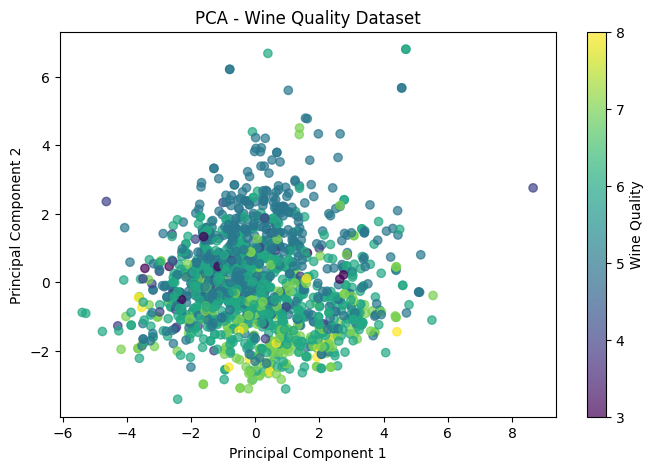

In [27]:
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="viridis", alpha=0.7)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Wine Quality Dataset")
plt.colorbar(label="Wine Quality")
plt.show()